# Movie Segmentation Using Expectation-Maximization

**Roll 68** · Assigned problem: segment movies by user ratings with EM clustering.

This notebook uses the shared `src/` pipeline. It must be run with the project root on `sys.path` (the first code cell adds it).

## 1. Problem and objectives

Cluster movies from the local MovieLens CSVs using Gaussian mixtures (EM) on **observed rating-share vectors**. Objectives: understand the tables, build valid features, fit and tune GMM, compare K-Means, compute a manual silhouette identity, and interpret clusters from rating profiles only.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src.data_loader import dataset_overview, load_raw, profile_frame
from src.preprocessing import FEATURE_COLS, feature_matrix, movie_rating_features
from src.clustering import compare_k_range, fit_gmm, fit_kmeans, manual_silhouette_example, pca_coords, recommend_k, silhouette_on_sample
from src.em_from_scratch import e_step, fit_em_1d, make_synthetic_1d, m_step, run_demo
from src.pipeline import persist_outputs, run_analysis

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.max_columns", 20)
print("ROOT", ROOT)


ROOT C:\ML MiniProject New


## 2. Dataset understanding

In [2]:
data = load_raw()
overview = dataset_overview(data)
display(pd.Series(overview))
print("ratings profile")
display(profile_frame(data["ratings"]))
print("movies profile")
display(profile_frame(data["movies"]))
ratings, movies = data["ratings"], data["movies"]
print("sample ratings")
display(ratings.head())
print("sample movies")
display(movies.head())


n_ratings                                                         100836
n_users                                                              610
n_movies_catalog                                                    9742
n_movies_rated                                                      9724
n_movies_unrated                                                      18
n_ratings_unmatched                                                    0
rating_min                                                           0.5
rating_max                                                           5.0
unique_ratings         [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, ...
n_tags                                                              3683
n_links                                                             9742
duplicate_ratings                                                      0
duplicate_movies                                                       0
missing_ratings        {'userId': 0, 'movieId': 0, 

ratings profile


,column,dtype,non_null,missing,unique
0,userId,int64,100836,0,610
1,movieId,int64,100836,0,9724
2,rating,float64,100836,0,10
3,timestamp,int64,100836,0,85043


movies profile


,column,dtype,non_null,missing,unique
0,movieId,int64,9742,0,9742
1,title,str,9742,0,9737
2,genres,str,9742,0,951


sample ratings


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


sample movies


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


There is no class label. Ratings are 0.5–5.0. Eighteen catalog titles have no ratings and are excluded from histograms. Tags/links are not modelling features.

## 3. Preprocessing and rating-share features

In [3]:
feat, prep = movie_rating_features(ratings, movies, min_ratings=20)
display(pd.Series(prep))
display(feat.head())
X = feature_matrix(feat)
print("X", X.shape, "row sums min/max", X.sum(1).min(), X.sum(1).max())
assert np.allclose(X.sum(1), 1.0)
assert prep["unmatched_titles"] == 0


min_ratings                                                                      20
n_rating_rows_input                                                          100836
n_invalid_or_dropped_ratings                                                      0
n_movies_with_any_valid_rating                                                 9724
n_movies_retained                                                              1297
n_movies_excluded                                                              8427
unmatched_titles                                                                  0
feature_row_sum_min                                                             1.0
feature_row_sum_max                                                             1.0
n_feature_dims                                                                   10
rating_levels                     [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 4.5, ...
dtype: object

,movieId,p_0_5,p_1_0,p_1_5,p_2_0,p_2_5,p_3_0,p_3_5,p_4_0,p_4_5,p_5_0,n_ratings,mean_rating,std_rating,title,genres
0,1,0.004651,0.000000,0.004651,0.027907,0.037209,0.158140,0.083721,0.381395,0.083721,0.218605,215,3.920930,0.832915,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,0.009091,0.009091,0.018182,0.045455,0.109091,0.254545,0.100000,0.327273,0.063636,0.063636,110,3.431818,0.877697,Jumanji (1995),Adventure|Children|Fantasy
2,3,0.019231,0.057692,0.019231,0.038462,0.038462,0.384615,0.096154,0.230769,0.000000,0.115385,52,3.259615,1.044631,Grumpier Old Men (1995),Comedy|Romance
3,5,0.020408,0.000000,0.040816,0.122449,0.040816,0.510204,0.020408,0.163265,0.020408,0.061224,49,3.071429,0.897843,Father of the Bride Part II (1995),Comedy
4,6,0.000000,0.009804,0.000000,0.019608,0.000000,0.225490,0.068627,0.362745,0.078431,0.235294,102,3.946078,0.813209,Heat (1995),Action|Crime|Thriller


X (1297, 10) row sums min/max 0.9999999999999998 1.0000000000000002


## 4. EM theory and from-scratch implementation

GMM: \(p(x)=\sum_k \pi_k \mathcal{N}(x\mid\mu_k,\Sigma_k)\).

E-step: responsibilities \(\gamma_{ik}\). M-step: weighted \(\pi,\mu,\Sigma\). The cell below fits **synthetic 1-D data**, not MovieLens.

converged

 True iters 7
weights [0.499 0.501]
means [-2.0218  2.209 ]
vars [0.2729 0.5183]
LL [-2.3574911896483535, -2.0229240554683376, -1.7332157257430134, -1.6218207272768108, -1.621517949772417, -1.6215134161876643, -1.6215132822444864]
from-scratch checks passed


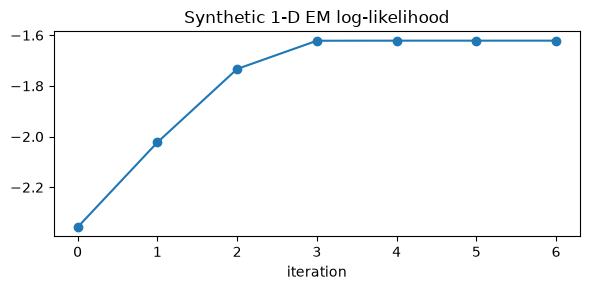

In [4]:
X1d, true_lab = make_synthetic_1d(n=400, seed=42)
demo = fit_em_1d(X1d, n_components=2, seed=42)
print("converged", demo.converged, "iters", demo.n_iter)
print("weights", demo.weights)
print("means", demo.means)
print("vars", demo.variances)
print("LL", demo.log_likelihoods)

# Responsibilities of one point sum to 1
resp, ll = e_step(X1d, demo.weights, demo.means, demo.variances)
assert np.allclose(resp.sum(1), 1.0)
w, m, v = m_step(X1d, resp)
assert np.isclose(w.sum(), 1.0)
assert np.all(np.diff(demo.log_likelihoods) >= -1e-8)
print("from-scratch checks passed")

plt.figure(figsize=(6, 3))
plt.plot(demo.log_likelihoods, marker="o")
plt.title("Synthetic 1-D EM log-likelihood")
plt.xlabel("iteration")
plt.tight_layout()
plt.show()


## 5. GMM modelling and K tuning

In [5]:
result = run_analysis(min_ratings=20, k=7, seed=42, data=data)
cmp = result["comparison"]
display(cmp)
print(result["recommendation"]["reason"])
print("selected K in this notebook:", result["config"]["k"])
print("converged", result["gmm"].converged, "n_iter", result["gmm"].n_iter)
print("AIC", result["gmm"].aic, "BIC", result["gmm"].bic, "mean LL", result["gmm"].inertia_or_ll)


,k,gmm_log_likelihood,gmm_aic,gmm_bic,gmm_converged,gmm_n_iter,gmm_silhouette,gmm_sizes,kmeans_inertia,kmeans_silhouette,kmeans_sizes
0,2,16.403348,-42469.201157,-42257.320981,True,7,0.247571,"[467, 830]",45.105161,0.282184,"[740, 557]"
1,3,17.473811,-45203.514811,-44883.110642,True,28,0.042346,"[634, 291, 372]",38.287090,0.211294,"[365, 453, 479]"
2,4,18.392989,-47547.034597,-47118.106435,True,20,0.025171,"[221, 213, 350, 513]",33.728206,0.202672,"[277, 331, 360, 329]"
3,5,18.315121,-47302.097682,-46764.645527,True,34,-0.020341,"[463, 151, 123, 389, 171]",30.444849,0.191464,"[232, 260, 323, 278, 204]"
4,6,18.972307,-48965.999453,-48320.023305,True,43,-0.048393,"[122, 190, 266, 453, 136, 130]",27.829107,0.188580,"[221, 247, 213, 215, 224, 177]"
5,7,19.334917,-49865.055348,-49110.555207,True,32,-0.037885,"[204, 139, 195, 96, 203, 336, 124]",26.306504,0.180033,"[257, 124, 197, 216, 150, 225, 128]"
6,8,19.154298,-49353.327400,-48490.303267,True,26,-0.056603,"[111, 77, 105, 68, 406, 154, 232, 144]",25.056721,0.171036,"[145, 232, 210, 104, 147, 199, 132, 128]"


BIC is minimised at K=7. AIC is minimised at K=7. GMM silhouette is highest at K=2. BIC penalises extra components more strongly than AIC and is used as the primary selection rule for this GMM. Silhouette measures geometric separation of hard assignments, not mixture likelihood, so it can disagree with AIC/BIC on overlapping clusters.
selected K in this notebook: 7
converged True n_iter 32
AIC -49865.05534763856 BIC -49110.55520672836 mean LL 19.334916811129556


## 6. K-Means baseline

In [6]:
print("GMM sizes", result["gmm"].sizes, "silhouette", result["gmm"].silhouette)
print("K-Means sizes", result["kmeans"].sizes, "silhouette", result["kmeans"].silhouette, "inertia", result["kmeans"].inertia_or_ll)


GMM sizes [204, 139, 195, 96, 203, 336, 124] silhouette -0.037884636950795386
K-Means sizes [257, 124, 197, 216, 150, 225, 128] silhouette 0.180032679292599 inertia 26.306503905244472


## 7. Evaluation and manual silhouette

In [7]:
m = result["manual_silhouette"]
print(m)
assert m["matches_sklearn"]
print(m["title"], "a=", round(m["a"], 6), "b=", round(m["b"], 6), "s=", round(m["s"], 6))


{'index': 115, 'cluster': 4, 'nearest_other_cluster': 3, 'a': 0.2625393789354751, 'b': 0.26049017438778466, 's': -0.007805322599601554, 'sklearn_s': -0.0078053225996021795, 'matches_sklearn': True, 'title': 'Bullets Over Broadway (1994)', 'movieId': 348}
Bullets Over Broadway (1994) a= 0.262539 b= 0.26049 s= -0.007805


## 8. Visualizations

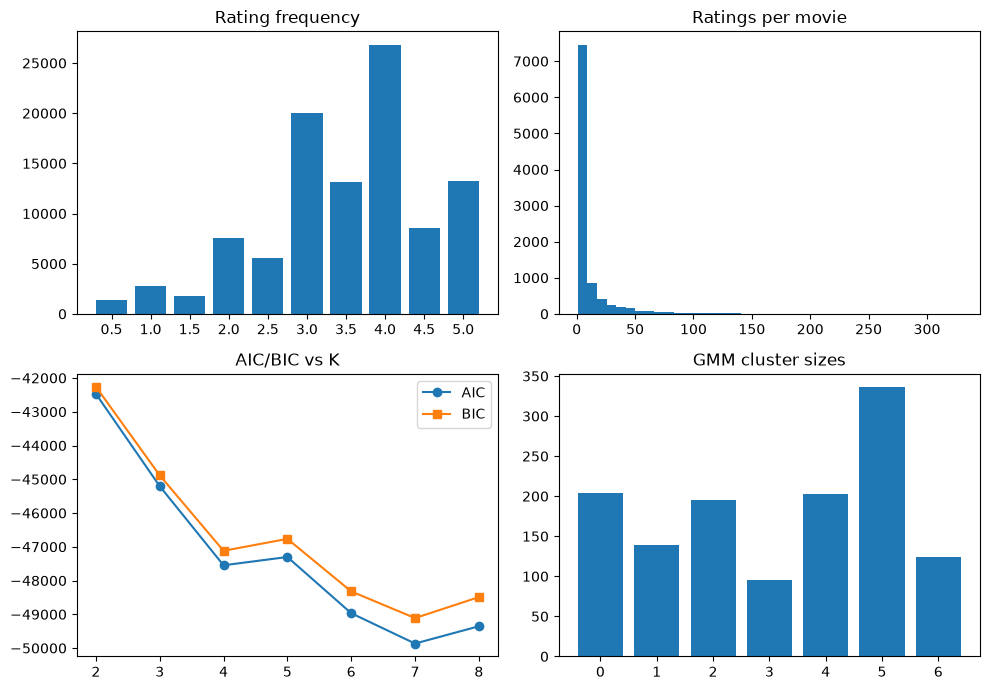

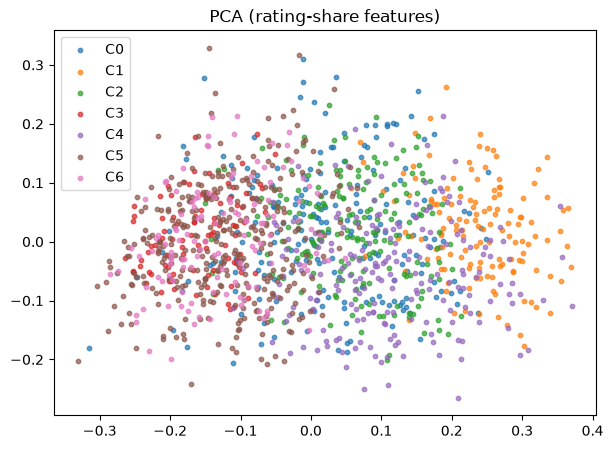

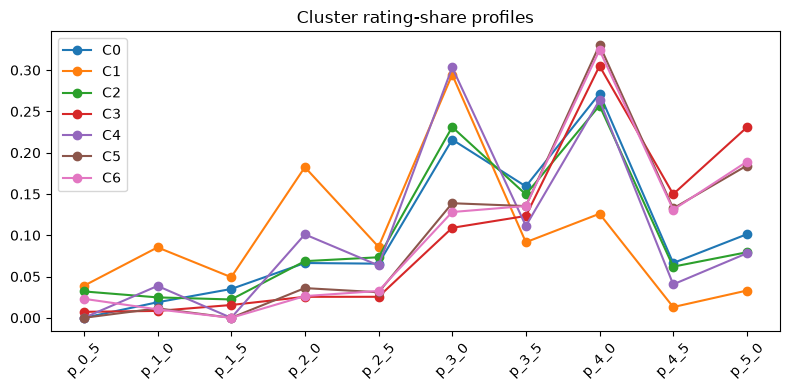

In [8]:
assigned = result["assigned"]
summary = result["summary"]

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
vc = ratings["rating"].value_counts().sort_index()
axes[0, 0].bar(vc.index.astype(str), vc.values)
axes[0, 0].set_title("Rating frequency")
axes[0, 1].hist(result["per_movie_counts"], bins=40)
axes[0, 1].set_title("Ratings per movie")
axes[1, 0].plot(cmp["k"], cmp["gmm_aic"], marker="o", label="AIC")
axes[1, 0].plot(cmp["k"], cmp["gmm_bic"], marker="s", label="BIC")
axes[1, 0].legend(); axes[1, 0].set_title("AIC/BIC vs K")
axes[1, 1].bar(summary["cluster"].astype(str), summary["n_movies"])
axes[1, 1].set_title("GMM cluster sizes")
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
for cid, g in assigned.groupby("cluster"):
    plt.scatter(g["pca_1"], g["pca_2"], s=10, alpha=0.7, label=f"C{cid}")
plt.legend(); plt.title("PCA (rating-share features)")
plt.show()

plt.figure(figsize=(8, 4))
for cid, g in assigned.groupby("cluster"):
    plt.plot(FEATURE_COLS, g[FEATURE_COLS].mean().values, marker="o", label=f"C{cid}")
plt.xticks(rotation=45); plt.legend(); plt.title("Cluster rating-share profiles")
plt.tight_layout(); plt.show()


## 9. Cluster interpretation

In [9]:
display(summary)
display(result["representatives"].groupby("cluster").head(3))
print("Do not treat high mean rating as 'quality' beyond the observed star mix.")
print("PCA variance", result["pca_var"])


,cluster,n_movies,share,mean_rating,mean_std_rating,mean_n_ratings,mean_max_responsibility,p_0_5,p_1_0,p_1_5,p_2_0,p_2_5,p_3_0,p_3_5,p_4_0,p_4_5,p_5_0
0,0,204,0.157286,3.463897,0.902092,44.857843,0.959487,0.000000,0.018859,0.034916,0.066391,0.065598,0.215904,0.159181,0.271520,0.066384,0.101246
1,1,139,0.107170,2.690513,1.016935,39.539568,0.969849,0.038789,0.085327,0.049221,0.182473,0.085994,0.294505,0.091583,0.126050,0.013036,0.033022
2,2,195,0.150347,3.315443,1.018759,55.230769,0.942189,0.031984,0.024756,0.022238,0.068650,0.073340,0.231099,0.149471,0.257078,0.061974,0.079409
3,3,96,0.074017,3.956473,0.891500,103.468750,0.929716,0.007257,0.008358,0.015535,0.025449,0.025471,0.109012,0.123377,0.305047,0.149812,0.230681
4,4,203,0.156515,3.326326,0.887491,37.596059,0.929930,0.000000,0.038601,0.000000,0.101050,0.063449,0.303323,0.111347,0.263576,0.040515,0.078140
5,5,336,0.259059,3.891297,0.801584,45.747024,0.961460,0.000000,0.011471,0.000000,0.036013,0.030953,0.138801,0.135362,0.330481,0.132545,0.184374
6,6,124,0.095605,3.845877,0.930315,76.975806,0.927053,0.023051,0.010239,0.000000,0.026314,0.032530,0.128152,0.135446,0.324232,0.130930,0.189107


,cluster,movieId,title,genres,n_ratings,mean_rating,std_rating,max_responsibility
0,0,55247,Into the Wild (2007),Action|Adventure|Drama,41,3.902439,0.871077,0.999979
1,0,1256,Duck Soup (1933),Comedy|Musical|War,23,3.804348,1.120356,0.999966
2,0,106072,Thor: The Dark World (2013),Action|Adventure|Fantasy|IMAX,21,3.309524,0.763391,0.999882
8,1,1562,Batman & Robin (1997),Action|Adventure|Fantasy|Thriller,42,2.214286,0.724921,1.000000
9,1,1882,Godzilla (1998),Action|Sci-Fi|Thriller,33,1.954545,0.829052,1.000000
10,1,1644,I Know What You Did Last Summer (1997),Horror|Mystery|Thriller,32,2.109375,0.974153,1.000000
16,2,6957,Bad Santa (2003),Comedy|Crime,26,3.365385,1.156567,1.000000
17,2,53996,Transformers (2007),Action|Sci-Fi|Thriller|IMAX,39,3.346154,1.081036,1.000000
18,2,112183,Birdman: Or (The Unexpected Virtue of Ignoranc...,Comedy|Drama,26,3.346154,1.191066,1.000000
24,3,912,Casablanca (1942),Drama|Romance,100,4.240000,0.895768,1.000000


Do not treat high mean rating as 'quality' beyond the observed star mix.
PCA variance [0.4472 0.1771]


## 10. Conclusion and limitations

**K = 7** minimises AIC and BIC on this run (seed 42, min 20 ratings, 1,297 movies). GMM silhouette is slightly negative because components overlap; K-Means is more compact but lacks soft membership. Limitations: MovieLens small, cold-start movies dropped, diagonal covariance, simplex geometry ignored. Original CSVs are not modified.

Re-save tables/figures:

In [10]:
paths = persist_outputs(result)
print("wrote", len(paths), "artifacts under output/")


wrote 13 artifacts under output/
